# 6. 최종 평가 및 결과 해석

서울시 따릉이 일별 수요 예측. [요구사항](../../docs/ml/REQUIREMENTS.md).

In [1]:
from pathlib import Path
import sys, json, time, joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

ROOT = Path.cwd()
if not (ROOT / "requirements.txt").exists():
    ROOT = ROOT.parents[1]
sys.path.insert(0, str(ROOT))
from src.ml.features import FEATURES, load_daily, make_features
from src.ml.splits import split_data, time_cv
from src.ml.models import model_candidates
from src.ml.evaluation import metrics, compare, grouped_metrics
from src.ml.tuning import tune_models
from sklearn.base import clone
from sklearn.inspection import permutation_importance

plt.rcParams.update({"figure.figsize": (10, 4), "font.family": "Malgun Gothic", "axes.unicode_minus": False})
OUT = ROOT / "outputs/ml"
OUT.mkdir(parents=True, exist_ok=True)
LOCAL = ROOT / "data/processed"
LOCAL.mkdir(parents=True, exist_ok=True)
daily = load_daily(ROOT)
frame = make_features(daily)
train, validation, final_train, test = split_data(frame)


,MAE,RMSE,WAPE,R2
model,,,,
train_mean,36256.4011,42014.2890,0.3650,-0.0298
lag_7,21046.7624,32580.6348,0.2119,0.3808
random_forest,18370.2580,24710.2779,0.1849,0.6438


,n,MAE,RMSE,WAPE,R2
group,,,,,
2026-01,31,10334.5698,12762.4224,0.2008,0.2155
2026-02,28,15102.3293,17717.1426,0.2424,0.2643
2026-03,31,13953.8130,20884.9532,0.1522,0.3171
2026-04,30,23345.9139,28514.9715,0.1831,-0.2057
2026-05,31,27341.0287,36163.3266,0.2170,-0.1664
2026-06,30,20042.0769,24646.6541,0.1479,0.1233


,n,MAE,RMSE,WAPE,R2
group,,,,,
0,26,17018.4520,21979.7871,0.1731,0.7276
1,26,12236.1134,16256.4663,0.1140,0.8285
2,25,21984.0795,33370.6200,0.2112,0.3975
3,26,19245.6348,26212.1644,0.1911,0.5561
4,26,20400.8829,24330.9388,0.1864,0.6407
5,26,20988.3057,25859.4321,0.2273,0.5925
6,26,16857.3309,22017.4164,0.2025,0.6782


,n,MAE,RMSE,WAPE,R2
group,,,,,
low,71,18705.2273,29622.9474,0.3451,-1.7525
middle,55,15795.9646,19628.9576,0.1435,-1.3633
high,55,20512.1366,22165.9360,0.1397,-6.3691


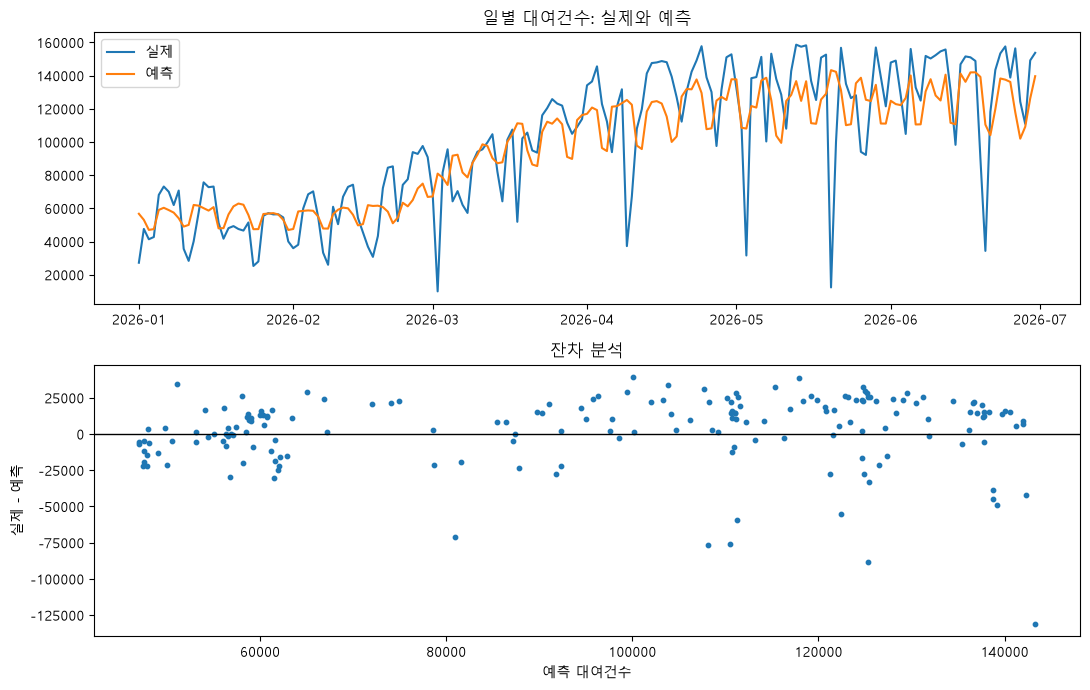

In [2]:
selection = json.loads((OUT / "05_selection.json").read_text(encoding="utf-8"))
model = clone(joblib.load(LOCAL / "ml_selected_pipeline.joblib"))
model.fit(final_train[FEATURES], final_train.rentals)
prediction = model.predict(test[FEATURES])
joblib.dump(model, LOCAL / "ml_final_pipeline.joblib")
scores = compare(test, {"train_mean": np.full(len(test), final_train.rentals.mean()),
                        "lag_7": test.lag_7.to_numpy(), selection["model"]: prediction})
scores.to_csv(OUT / "06_test_metrics.csv")
display(scores.round(4))
detail = test[["date", "rentals"]].copy()
detail["prediction"] = prediction
detail["residual"] = detail.rentals - prediction
detail["absolute_error"] = detail.residual.abs()
detail["month"] = detail.date.dt.strftime("%Y-%m")
detail["weekday"] = detail.date.dt.dayofweek
q1, q2 = final_train.rentals.quantile([1/3, 2/3]).to_numpy()
detail["demand_band"] = pd.cut(detail.rentals, [-np.inf, q1, q2, np.inf], labels=["low", "middle", "high"])
detail.to_csv(LOCAL / "ml_test_predictions.csv", index=False)
for column in ("month", "weekday", "demand_band"):
    grouped = grouped_metrics(detail, column)
    grouped.to_csv(OUT / f"06_{column}.csv")
    display(grouped.round(4))
fig, axes = plt.subplots(2, 1, figsize=(11, 7))
axes[0].plot(detail.date, detail.rentals, label="실제")
axes[0].plot(detail.date, detail.prediction, label="예측")
axes[0].legend()
axes[0].set_title("일별 대여건수: 실제와 예측")
axes[1].scatter(detail.prediction, detail.residual, s=10)
axes[1].axhline(0, color="black", linewidth=1)
axes[1].set(xlabel="예측 대여건수", ylabel="실제 - 예측", title="잔차 분석")
plt.tight_layout()
plt.savefig(OUT / "06_predictions_residuals.png", dpi=120)
plt.show()


- 선정 모델의 테스트 MAE 18,370건, RMSE 24,710건, WAPE 18.49%임.
- 전주 동일 요일 기준선 대비 MAE가 12.72% 감소함.
- 월별 MAE가 가장 큰 시기는 2026-05이며 계절별 오차가 균일하지 않음.
- 테스트는 기존 EDA에서 관찰한 2026년 상반기로, 완전히 새로운 기간의 성능을 보장하지 않음.

,feature,MAE_increase,std
3,rolling_7,8156.746,836.200
8,year_cos,4694.392,643.557
1,lag_7,1727.570,321.067
4,rolling_28,1546.867,233.053
0,lag_2,822.901,127.758
5,dow_sin,516.502,330.678
9,weekend,139.308,234.186
7,year_sin,65.410,76.890
2,lag_14,26.080,64.248
6,dow_cos,1.829,5.275


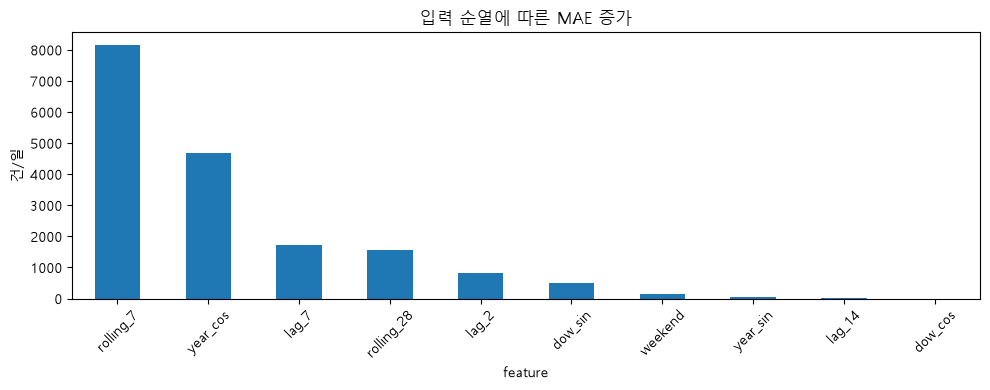

C:\Users\SSAFY\AppData\Local\Temp\ipykernel_15216\182706153.py:13: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  display(worst.round(1))


,date,rentals,prediction,residual
475,2026-05-20,12363,143281.9,-130918.9
434,2026-04-09,37256,125326.4,-88070.4
458,2026-05-03,31609,108104.1,-76495.1
506,2026-06-20,34376,110475.7,-76099.7
396,2026-03-02,9975,80948.3,-70973.3


555

In [3]:
# Interpretation only: no model selection or tuning uses these test diagnostics.
importance = permutation_importance(model, test[FEATURES], test.rentals,
    scoring="neg_mean_absolute_error", n_repeats=10, random_state=42, n_jobs=1)
importance_table = pd.DataFrame({"feature": FEATURES, "MAE_increase": importance.importances_mean,
                                 "std": importance.importances_std}).sort_values("MAE_increase", ascending=False)
importance_table.to_csv(OUT / "06_importance.csv", index=False)
display(importance_table.round(3))
importance_table.set_index("feature").MAE_increase.plot.bar(title="입력 순열에 따른 MAE 증가", ylabel="건/일", rot=45)
plt.tight_layout()
plt.savefig(OUT / "06_importance.png", dpi=120)
plt.show()
worst = detail.nlargest(5, "absolute_error")[["date", "rentals", "prediction", "residual"]]
display(worst.round(1))
# Public notebooks show only a few error examples; full daily records remain untracked.
(LOCAL / "ml_error_examples.json").write_text(worst.to_json(orient="records", date_format="iso"), encoding="utf-8")


- 순열 중요도에서 rolling_7의 평균 MAE 증가가 8,157건으로 가장 큼.
- 중요도는 모델의 입력 의존도이며 수요에 대한 인과효과를 의미하지 않음.
- 지연값·이동평균은 서로 연관되어 개별 중요도가 분산될 수 있음.
- 큰 오류의 원인을 날씨·공휴일로 단정할 수 없으며 후속 데이터로 확인해야 함.